# A Whole Analysis In One Chain

**Version**: 1

**Last modified**: 2026-10-12

**Compatible with opengate-gate-tree version:** 0.5.0

**Author**: Mateusz Jakub Bała

## About

The other notebooks take one step each. This one takes all of them, on a file
written by a PET scanner: read the file and recognise what it holds, keep the
hits in one part of the scanner, keep the gammas that scattered, convert the
energies, measure the scattering angle, draw it, write the result to a file and
put a statistics report beside it.

The point is how short that is once each step is known — and the two places
where a chain goes wrong without saying so: two selections combined row by row
when they do not hold the same rows, and a written file that no longer says
which entries its rows came from.

## What will you learn from this notebook

- how to recognise the structure of a file before reading it
- how to combine a geometric filter, a selection by process and the order of
  hits within a track
- how to read vectors out of a frame and why two views combine only when they
  describe the same rows
- how to convert units in the middle of a chain
- how to write the result so that its rows can still be traced back, and what a
  statistics report of a selection describes
- how the whole analysis fits in one cell

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.5.0
python: 3.14.5
run on: 2026-10-12


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

The file is a small GATE output carried in the repository: 500 hits of a
"Hits" tree written by a simulation with a `cylindricalPET` system, described
in [`../data/README.md`](../data/README.md).

In [2]:
output = paths.output_dir("tutorial-17-whole-analysis-in-one-chain")
example_input = paths.input_example("hits-a2-cylindrical-pet.root")

In [3]:
import numpy as np

from opengate_gate_tree import (
    GammaType,
    GateTree,
    OutputFileFormat,
    RootFile,
    TreeData,
    build_output_file_path,
    build_statistics_file_path,
    compute_statistics,
    format_statistics,
    summarise_hits_tree,
    write_statistics,
    write_tree,
)

### Reading The File

What the "Hits" tree is, before anything is read — the structure decides which
branches exist:

In [4]:
with RootFile(example_input) as root_file:
    detection = root_file.detect_hits_tree()
    data = root_file.read(GateTree.HITS)

print(summarise_hits_tree(detection))
data

Hits tree variant: System (A2), stored as 'Hits', system cylindricalPET / OPET, 46 branches


TreeData(tree='Hits', entries=500, branches=46)

A tree with a system: besides the forty branches of a tree without one, it
holds the six identifiers of the `cylindricalPET` hierarchy, from `gantryID`
down to `layerID`. Reading it checked the tree against that structure, so every
branch used below is known to be there.

In [5]:
frame = data.to_dataframe()

### What The Data Shows

Where the hits are, in millimetres, as GATE writes positions:

In [6]:
radius = np.hypot(frame["posX"], frame["posY"])

along = frame["posZ"]

{
    "distance from the axis [mm]": (round(float(radius.min()), 1), round(float(radius.max()), 1)),
    "along the axis [mm]": (round(float(along.min()), 1), round(float(along.max()), 1)),
}

{'distance from the axis [mm]': (410.2, 430.4),
 'along the axis [mm]': (-529.2, 518.5)}

A ring 20 mm deep, starting 410 mm from the axis and reaching more than half
a metre to either side along it — the crystals of the scanner. What were the
gammas?

In [7]:
{
    "particles": frame["PDGEncoding"].unique().tolist(),
    "source positions": frame[["sourcePosX", "sourcePosY", "sourcePosZ"]]
    .drop_duplicates()
    .to_numpy()
    .tolist(),
    "every gammaType is UNKNOWN": bool(
        frame["gammaType"].gate.is_gamma_type(GammaType.UNKNOWN).all()
    ),
}

{'particles': [22],
 'source positions': [[0.0, 0.0, 0.0]],
 'every gammaType is UNKNOWN': True}

Gammas from the origin, and `gammaType` says nothing about them: a gamma not
written by a `PositroniumSource` is `UNKNOWN`. A selection by gamma type would
keep every row here, so the selection below is by process instead. The energy
of a gamma absorbed whole is the energy it carried:

In [8]:
TRACK_KEY = ["runID", "eventID", "trackID"]

frame.groupby(TRACK_KEY)["edep"].sum().round(4).value_counts().head(3)

edep
0.5110    228
0.1666      1
0.0949      1
Name: count, dtype: int64

Two hundred and twenty-eight tracks sum to 0.511 MeV, and no other sum comes
close to being as common: annihilation gammas of 511 keV, as in a PET scan.

### The Question

*In the central 200 mm of the scanner, at what angle did a gamma scatter the
first time it interacted, and what energy did that scattering leave?*

The first and the second hit of every track, by time. Both tables are indexed
by the track, so that they can be matched row by row:

In [9]:
ordered = frame.sort_values([*TRACK_KEY, "time"], kind="stable")
hit_order = ordered.groupby(TRACK_KEY).cumcount()

first = ordered[hit_order == 0].set_index(TRACK_KEY)
second = ordered[hit_order == 1].set_index(TRACK_KEY)
len(first), len(second)

(259, 166)

Of 259 tracks, 166 have a second hit. The first hits that are Compton
scatterings with a second hit to follow, and of those the ones in the central
slice of the scanner — a ring around the axis, 200 mm long:

In [10]:
scattered = first.loc[second.index]
scattered = scattered[scattered["processName"].gate.is_process("Compton")]

central = scattered.gate.in_cylinder(
    (0.0, 0.0),
    radius=500.0,
    inner_radius=400.0,
    z_range=(-100.0, 100.0),
)
len(scattered), len(central)

(166, 52)

Every one of the 166 first hits with a second hit to follow is a Compton
scattering, and 52 of them lie in the central slice. The ring is wider than the
crystals — from 400 to 500 mm — so it decides the slice along the axis and
cuts nothing off around it. Its surfaces belong to it, so a hit exactly on one
of them would count as inside.

### Vectors, And The Rows They Describe

The direction before the scattering runs from the source to the first hit, and
the direction after it from the first hit to the second. Each is a difference
of two `VectorView`s — and two views combine only when they describe the same
rows. The second hits of **every** scattered track against the first hits of
the central ones:

In [11]:
try:
    second.gate.position() - central.gate.position()
except ValueError as error:
    print(error)

Two views are combined row by row, so they describe the same rows: got 166 row(s) against 52, with different index values. Select the rows first, then read the vectors.


Plain pandas would align the two by index and fill the rest with `nan`; NumPy
would zip them by position and pair one track's hit with another's. A view
refuses instead. Selecting the second hits of the same tracks first is what
makes the subtraction mean something:

In [12]:
following = second.loc[central.index]

incoming = central.gate.position() - central.gate.source_position()
outgoing = following.gate.position() - central.gate.position()

angle = incoming.angle_to(outgoing).gate.rad_to_deg()
angle.head()

runID  eventID  trackID
0      31       2          115.175796
       42       2           68.017124
       45       2           79.991612
       52       2           86.470165
       55       2           52.553772
Name: angle, dtype: float64

The angle comes back as a column, with the index of the rows it was computed
for — the tracks — so it can be put back beside them. The energy, converted
from the MeV GATE writes to keV, keeps that index too:

In [13]:
energy = central["edep"].gate.MeV_to_keV()
energy.head()

runID  eventID  trackID
0      31       2          299.174339
       42       2          185.757712
       45       2          226.049662
       52       2          256.810129
       55       2          147.300795
Name: edep, dtype: float64

### The Answer, Drawn

The energy against the angle, beside the Compton formula for a 511 keV gamma
on an electron at rest — which the tutorial on Compton scattering derives:

<Axes: title={'center': 'First scattering in the central 200 mm'}, xlabel='scattering angle [deg]', ylabel='energy deposited [keV]'>

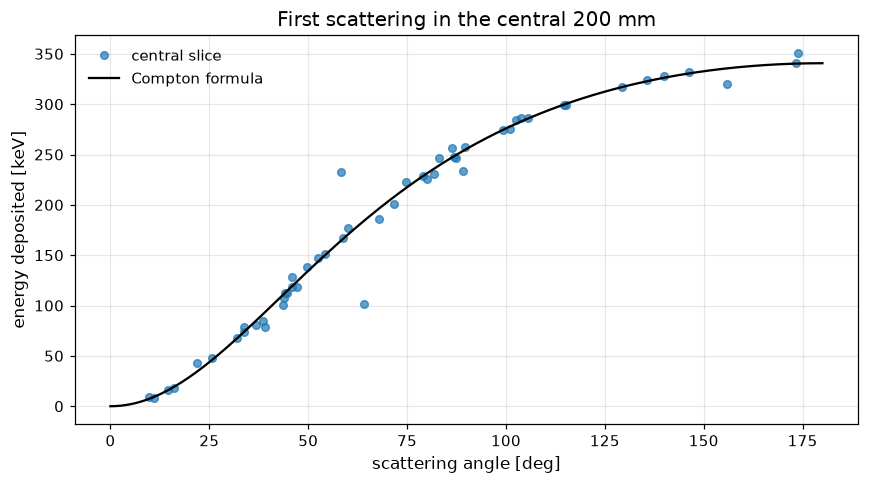

In [14]:
curve = np.linspace(0.0, np.pi, 200)
compton = 511.0 - 511.0 / (1.0 + (511.0 / 510.999) * (1.0 - np.cos(curve)))

plotting.plot_graphs(
    [
        plotting.GraphParams(angle, energy, label="central slice", alpha=0.7),
        plotting.GraphParams(
            np.rad2deg(curve),
            compton,
            label="Compton formula",
            marker="",
            linestyle="-",
            color="black",
        ),
    ],
    xtitle="scattering angle [deg]",
    ytitle="energy deposited [keV]",
    title="First scattering in the central 200 mm",
)

The points follow the curve, as they should when the directions were rebuilt
from the right pairs of hits; the two or three that stray from it are the kind
the tutorial on Compton scattering looks into.

### Writing The Result

One table: the position of the scattering, the energy in keV and the angle in
degrees, each column named with its unit so that nobody reading the file has
to guess. `TreeData.from_dataframe` drops the index, and the index is where the
track identifiers are — so they are turned back into columns first:

In [15]:
result = (
    central[["posX", "posY", "posZ"]].assign(edepKeV=energy, scatteringAngleDeg=angle).reset_index()
)
result_data = TreeData.from_dataframe(GateTree.HITS, result)
result_data.branch_names

('runID',
 'eventID',
 'trackID',
 'posX',
 'posY',
 'posZ',
 'edepKeV',
 'scatteringAngleDeg')

Without `reset_index()`, the file would hold 52 rows and nothing to say which
event and track each of them was. The identifiers are written as GATE wrote
them, so a row can be traced back to the simulation that made it.

The file is named the way the command line names its outputs, and HDF5 is the
format to pick when the next step is Python:

In [16]:
title = "central-first-scattering"

result_path = write_tree(
    result_data,
    build_output_file_path(output, title, GateTree.HITS, OutputFileFormat.HDF5),
    OutputFileFormat.HDF5,
)
result_path.name

'central-first-scattering.hits.hdf5'

### The Report Beside It

A statistics report of what was written, saved next to it:

In [17]:
report = compute_statistics(result_data)
report_path = write_statistics(report, build_statistics_file_path(output, title, GateTree.HITS))

print(report_path.name)
print(format_statistics(report))

central-first-scattering.hits.stats.json
Tree: Hits
Entries: 52
Events: 39 (counted by runID, eventID)
Runs: 1
Tracks: 52 (counted by runID, eventID, trackID)
Branches (8):
  - runID / int32: min 0, max 0, mean 0, std 0, 1 distinct
  - eventID / int32: min 31, max 211, mean 123.712, std 51.0759, 39 distinct
  - trackID / int32: min 1, max 2, mean 1.53846, std 0.498519, 2 distinct
  - posX / float32: min -419.472, max 420.742, mean 86.5914, std 284.502
  - posY / float32: min -411.959, max 423.534, mean 32.7219, std 290.033
  - posZ / float32: min -96.8734, max 97.1052, mean 5.24833, std 51.4407
  - edepKeV / float64: min 8.03594, max 350.898, mean 184.988, std 101.013
  - scatteringAngleDeg / float64: min 9.79277, max 173.754, mean 73.0694, std 41.2632


The report describes the selection, not the file: 39 events here, out of the
149 the file holds. That is what a report written after a filter is for — it
says how much of the data survived the question — but it is not a summary of
the simulation, and it should not be read as one.

### The Whole Chain In One Cell

Everything above, without the looking around:

In [18]:
with RootFile(example_input) as root_file:
    hits = root_file.read(GateTree.HITS).to_dataframe()

hits = hits.sort_values([*TRACK_KEY, "time"], kind="stable")
order = hits.groupby(TRACK_KEY).cumcount()
first_hits = hits[order == 0].set_index(TRACK_KEY)
second_hits = hits[order == 1].set_index(TRACK_KEY)

chosen = first_hits.loc[second_hits.index]
chosen = chosen[chosen["processName"].gate.is_process("Compton")]
chosen = chosen.gate.in_cylinder((0.0, 0.0), 500.0, inner_radius=400.0, z_range=(-100.0, 100.0))
after = second_hits.loc[chosen.index]

answer = (
    chosen[["posX", "posY", "posZ"]]
    .assign(
        edepKeV=chosen["edep"].gate.MeV_to_keV(),
        scatteringAngleDeg=(chosen.gate.position() - chosen.gate.source_position())
        .angle_to(after.gate.position() - chosen.gate.position())
        .gate.rad_to_deg(),
    )
    .reset_index()
)

answer.equals(result)

True

About fifteen lines from the file to the answer, and the same answer as the
step-by-step version. Every line is something an earlier notebook explained;
what this one adds is that they fit together without glue — each step takes a
frame or a column and gives one back, with the index of the rows it kept.

## Summary

A whole analysis — recognising the file, selecting by geometry, process and
order within a track, converting units, measuring an angle, drawing it, and
writing the result with a report beside it — is a chain of steps that each
take a frame and give one back. Combine vectors only of the same rows, turn
the index into columns before writing, and read a report of a selection as a
report of the selection.

## Bibliography

- [The "Hits" Tree](https://opengate-gate-tree.readthedocs.io/en/latest/guide/hits.html)
  — the structures a tree is recognised as, and the identifiers of a system
- [Filtering and selecting](https://opengate-gate-tree.readthedocs.io/en/latest/guide/filtering.html)
  — shapes, processes, and what follows a selection
- [Vectors and angles](https://opengate-gate-tree.readthedocs.io/en/latest/guide/vectors.html)
  — views, the rule about rows, and the scattering angle
- [Units](https://opengate-gate-tree.readthedocs.io/en/latest/guide/units.html)
  — conversions in a chain
- [Exporting files](https://opengate-gate-tree.readthedocs.io/en/latest/guide/export.html)
  — formats and the names of output files
- [Statistics](https://opengate-gate-tree.readthedocs.io/en/latest/guide/statistics.html)
  — what a report holds
- [Event identifiers](https://opengate-gate-tree.readthedocs.io/en/latest/guide/events.html)
  — why a track is named by three identifiers

## Changelog

- v1: written.